Punto 4.1 Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40,
80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal,
y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.

- Por la frecuencia de Nyquist se tiene que la frecuencia de muestreo debe ser minimo el doble de nuestra mayor frecuencia en este caso 160 Hz, así se tendria que la minima necesaria es 320 Hz, y se utilizará una de 1000 Hz siguiendo el ejemplo de la guía.
 

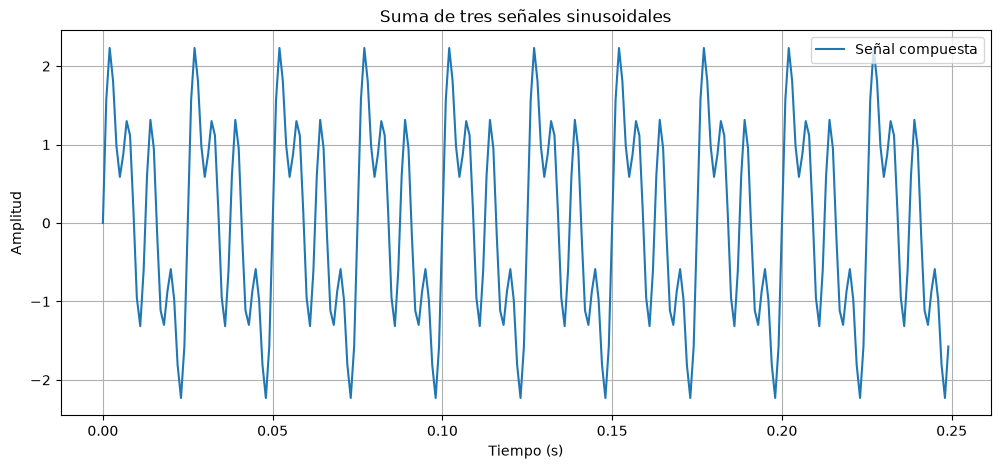

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Frecuencias de las componentes
F1 = 40
F2 = 80
F3 = 160

# Frecuencia de muestreo
Fs = 1000
T = 1 / Fs

# Frecuencia fundamental y periodo
Fo = 40
Tp = 1 / Fo

t = np.arange(0, 10 * Tp, T)

# Componentes sinusoidales
x1 = np.sin(2 * np.pi * F1 * t)
x2 = np.sin(2 * np.pi * F2 * t)
x3 = np.sin(2 * np.pi * F3 * t)

# Señal compuesta
x = x1 + x2 + x3

# Graficar
plt.figure(figsize=(12, 5))
plt.plot(t, x, label="Señal compuesta")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Suma de tres señales sinusoidales")
plt.grid(True)
plt.legend()
plt.show()


Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia.
Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos
de la señal).

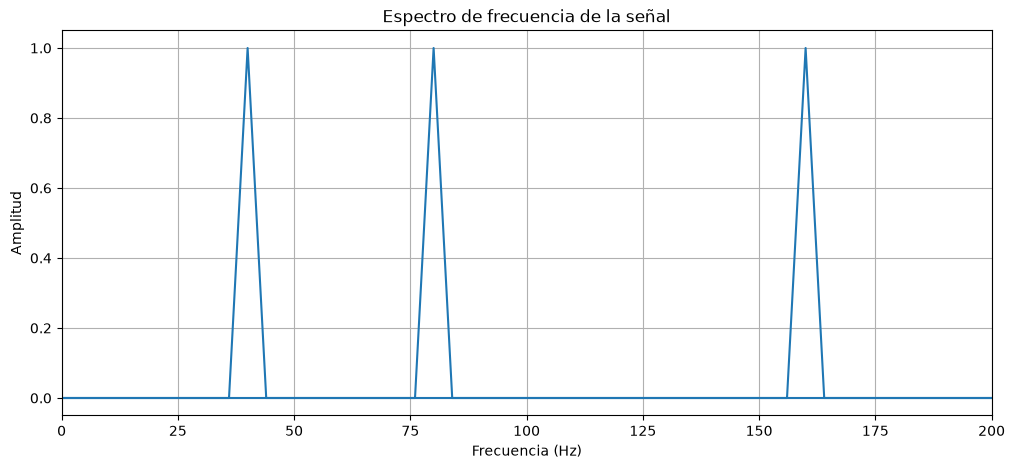

In [2]:

# Número de muestras
N = len(x)

# Calcular la FFT
X = np.fft.fft(x)

# Crear el eje de frecuencias
F = np.fft.fftfreq(N, d=1/Fs)

# Obtener la mitad positiva del espectro
Nmitad = N // 2 + 1
Fmitad = F[:Nmitad]

# Calcular el espectro de amplitud
amplitud = np.abs(X[:Nmitad]) / N

# Duplicar las componentes de frecuencia positiva
# excepto DC y Nyquist
amplitud[1:-1] *= 2

# Graficar el espectro
plt.figure(figsize=(12, 5))
plt.plot(Fmitad, amplitud)

plt.title("Espectro de frecuencia de la señal")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0, 200)
plt.grid(True)
plt.show()


Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier.
Aplíquelo a la señal anterior.

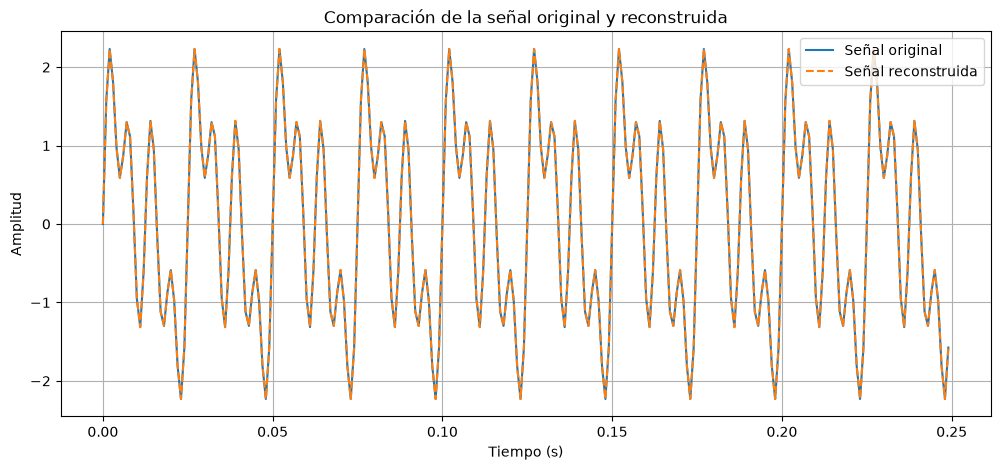

In [4]:

# Calcular la transformada inversa
xr = np.fft.ifft(X)

# Obtener la parte real
xr = np.real(xr)

# Graficar la señal original y reconstruida
plt.figure(figsize=(12, 5))

plt.plot(t, x, label="Señal original")
plt.plot(t, xr, '--', label="Señal reconstruida")

plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Comparación de la señal original y reconstruida")
plt.legend()
plt.grid(True)
plt.show()



¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué?
- Sí, las lineas de codigo presentadas aplican un filtro a la señal deseada y solo se queda con los coeficientes de la transformada de Fourier correspondientes a los índices del 9 al 12 y eliminan los demás al asignarles un valor de cero

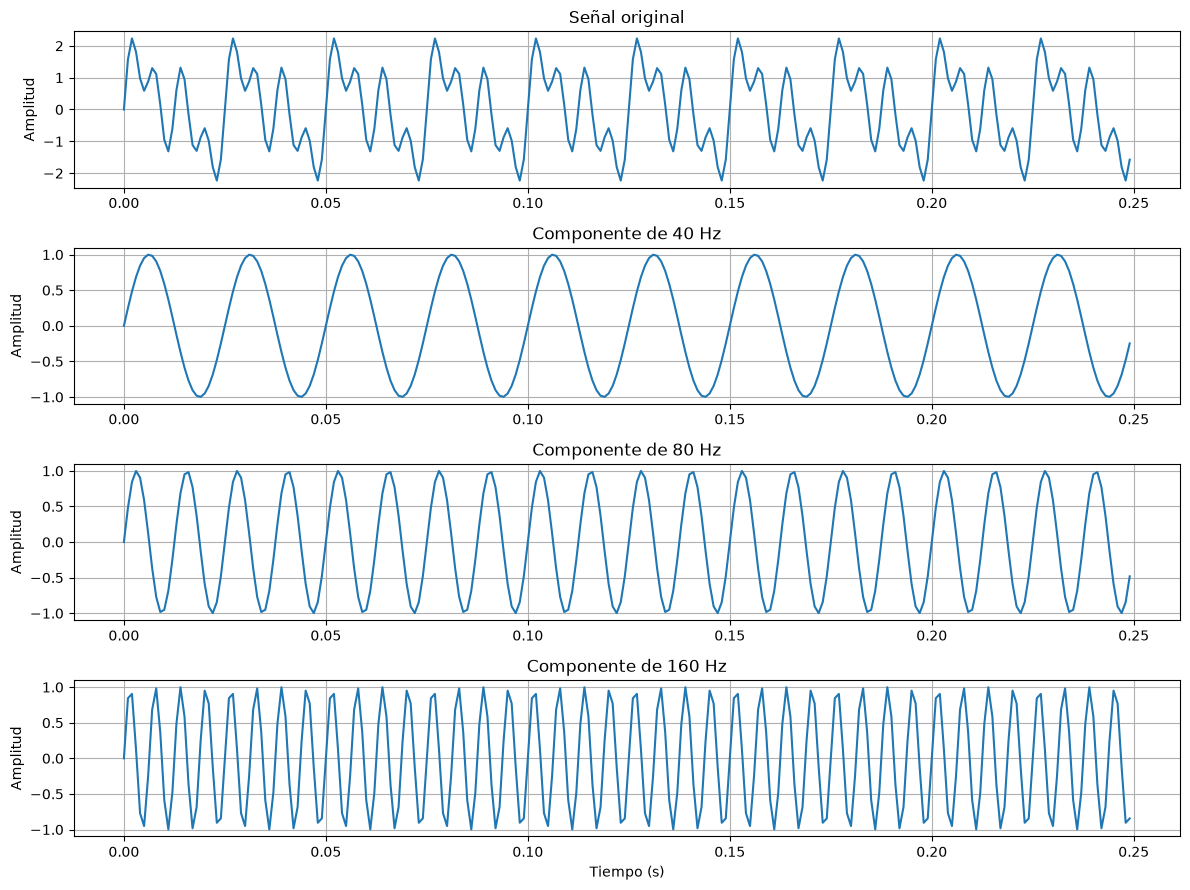

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Transformada de Fourier de la señal original
X = np.fft.fft(x)
N = len(x)

# Crear espectros filtrados
F40 = np.zeros(N, dtype=complex)
F80 = np.zeros(N, dtype=complex)
F160 = np.zeros(N, dtype=complex)

# Conservar las frecuencias positivas y negativas
F40[10] = X[10]
F40[240] = X[240]

F80[20] = X[20]
F80[230] = X[230]

F160[40] = X[40]
F160[210] = X[210]

# Aplicar la transformada inversa
x40 = np.real(np.fft.ifft(F40))
x80 = np.real(np.fft.ifft(F80))
x160 = np.real(np.fft.ifft(F160))

# Graficar la señal original y las componentes
plt.figure(figsize=(12, 9))

plt.subplot(4, 1, 1)
plt.plot(t, x)
plt.title("Señal original")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t, x40)
plt.title("Componente de 40 Hz")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t, x80)
plt.title("Componente de 80 Hz")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(t, x160)
plt.title("Componente de 160 Hz")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()


El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de
muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas
de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que
se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de
Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning,
y justificar la elección del solapamiento y el ancho de la ventaja)

Número de muestras: 1250
Duración: 5.0 segundos


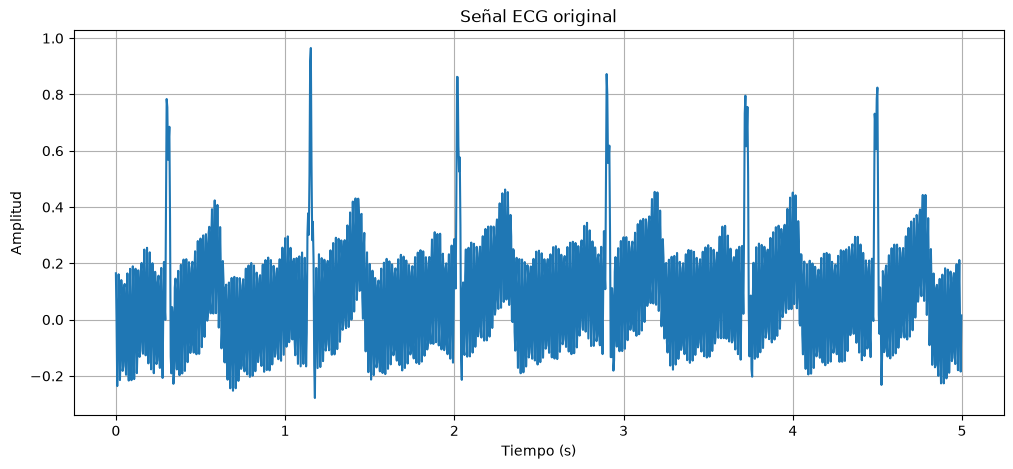

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import welch

# Cargar archivo
datos = loadmat("senecg.mat")

# Extraer la señal ECG
ecg = datos["ECG"].flatten()

# Frecuencia de muestreo
Fs = 250

# Número de muestras
N = len(ecg)

# Vector de tiempo
t = np.arange(N) / Fs

# Mostrar información
print("Número de muestras:", N)
print("Duración:", N/Fs, "segundos")

# Graficar ECG original
plt.figure(figsize=(12, 5))
plt.plot(t, ecg)
plt.title("Señal ECG original")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()


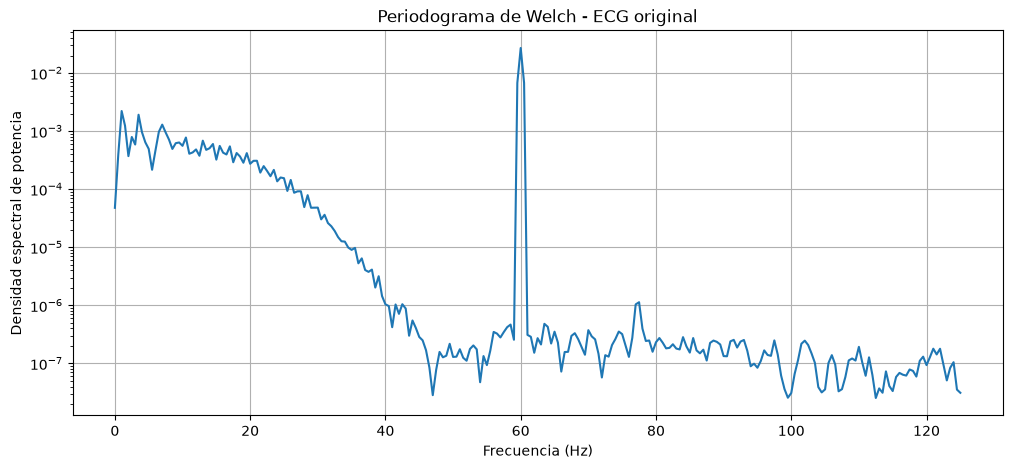

In [8]:

# Parámetros del método de Welch
ventana = 500
solapamiento = 250

# Calcular el periodograma de Welch
f, Pxx = welch(
    ecg,
    fs=Fs,
    window="hann",
    nperseg=ventana,
    noverlap=solapamiento
)

# Graficar densidad espectral de potencia
plt.figure(figsize=(12, 5))

plt.semilogy(f, Pxx)

plt.title("Periodograma de Welch - ECG original")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Densidad espectral de potencia")
plt.grid(True)
plt.show()


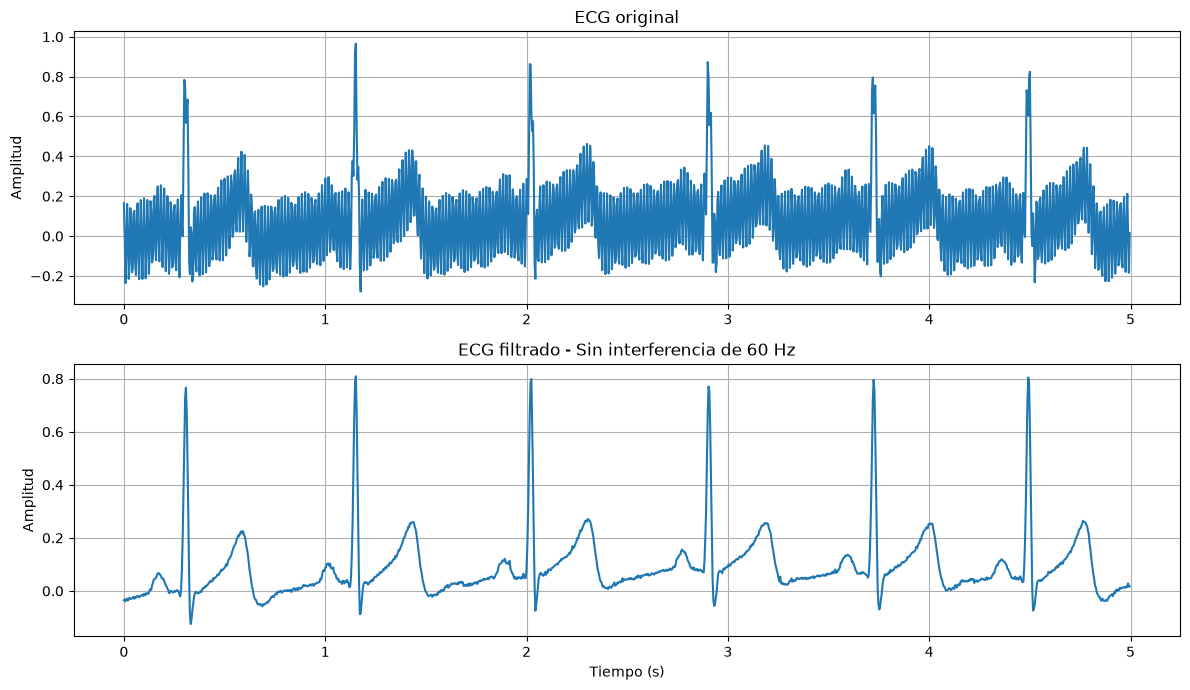

In [9]:

# Calcular FFT de la señal ECG
X = np.fft.fft(ecg)

# Crear eje de frecuencias
F = np.fft.fftfreq(N, d=1/Fs)

# Copiar los coeficientes originales
X_filtrada = X.copy()

# Eliminar frecuencias cercanas a +60 y -60 Hz
X_filtrada[np.abs(np.abs(F) - 60) < 0.5] = 0

# Aplicar la transformada inversa de Fourier
ecg_filtrada = np.real(np.fft.ifft(X_filtrada))

# Graficar las dos señales
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, ecg)
plt.title("ECG original")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, ecg_filtrada)
plt.title("ECG filtrado - Sin interferencia de 60 Hz")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()


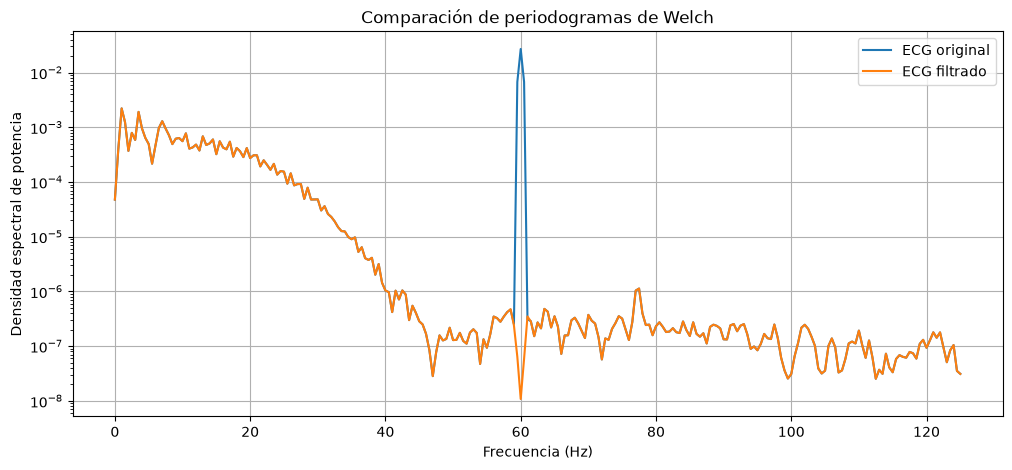

In [10]:

# Periodograma de la señal filtrada
f2, Pxx_filtrada = welch(
    ecg_filtrada,
    fs=Fs,
    window="hann",
    nperseg=500,
    noverlap=250
)

# Comparar periodogramas
plt.figure(figsize=(12, 5))

plt.semilogy(f, Pxx, label="ECG original")
plt.semilogy(f2, Pxx_filtrada, label="ECG filtrado")

plt.title("Comparación de periodogramas de Welch")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Densidad espectral de potencia")
plt.legend()
plt.grid(True)
plt.show()


Realice un análisis de frecuencia a través del periodograma de welch de una señal de ECG
de un paciente Sano y otra de un sujeto con una arritmia en la que hayan identificado que
presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis
comparativo de las señales según lo que le indiquen los periodogramas. (Usar una ventana
Hanning, y justificar la elección del solapamiento y el ancho de la ventaja)

In [ ]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch

FS = 500  
REGISTROS = {
    'Ritmo sinusal (SR)': 'MUSE_20180209_172046_21000',
    'Fibrilación auricular (AFIB)': 'MUSE_20180113_074740_85000',
}
N_PER_SEG = 1000  # 2 s
N_OVERLAP = 500   # 50 %
DERIVACION = 'II'


def encontrar_csv(nombre):
    raiz = Path('.')
    rutas = list(raiz.rglob(nombre + '.csv'))
    if rutas:
        return rutas[0].read_bytes()
    zips = list(raiz.rglob('ECGDataDenoised*.zip'))
    for ruta_zip in zips:
        with ZipFile(ruta_zip) as z:
            coincidencias = [x for x in z.namelist() if Path(x).name.lower() == (nombre + '.csv').lower()]
            if coincidencias:
                return z.read(coincidencias[0])
    raise FileNotFoundError(f'No se encontró {nombre}.csv en carpetas o en ECGDataDenoised.zip')


def cargar_derivacion_ii(nombre):
    contenido = encontrar_csv(nombre)
    # Archivos Chapman suelen tener 12 columnas (derivaciones) y 5000 filas.
    # Se intenta primero lectura con encabezados; si no los hay, lectura numérica.
    df = pd.read_csv(BytesIO(contenido))
    nombres = {str(c).strip().upper(): c for c in df.columns}
    if DERIVACION in nombres:
        y = pd.to_numeric(df[nombres[DERIVACION]], errors='coerce').to_numpy()
    else:
        df = pd.read_csv(BytesIO(contenido), header=None)
        datos = df.apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
        # Orden estándar de Chapman: I, II, III, aVR, aVL, aVF, V1...V6
        if datos.shape[1] == 12:
            y = datos[:, 1]
        elif datos.shape[0] == 12:
            y = datos[1, :]
        else:
            raise ValueError(f'Forma inesperada de {nombre}.csv: {datos.shape}. Revise encabezados/derivaciones.')
    if not np.all(np.isfinite(y)):
        raise ValueError(f'El registro {nombre} contiene valores no numéricos o faltantes.')
    if len(y) < N_PER_SEG:
        raise ValueError(f'El registro {nombre} tiene menos de {N_PER_SEG} muestras.')
    return y


senales = {etiqueta: cargar_derivacion_ii(nombre) for etiqueta, nombre in REGISTROS.items()}

fig, axs = plt.subplots(2, 1, figsize=(12, 7))
for ax, (etiqueta, y) in zip(axs, senales.items()):
    tiempo = np.arange(len(y)) / FS
    ax.plot(tiempo, y, linewidth=0.8)
    ax.set(title=f'{etiqueta} — derivación II', xlabel='Tiempo (s)', ylabel='Amplitud (unidades del CSV)')
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('chapman_ecg_tiempo.png', dpi=180)

fig, ax = plt.subplots(figsize=(12, 5))
resultados = {}
for etiqueta, y in senales.items():
    f, pxx = welch(y, fs=FS, window='hann', nperseg=N_PER_SEG,
                   noverlap=N_OVERLAP, detrend='constant', scaling='density')
    resultados[etiqueta] = (f, pxx)
    ax.semilogy(f, np.maximum(pxx, np.finfo(float).tiny), label=etiqueta)
    idx = np.argmax(pxx[1:]) + 1
    print(f'{etiqueta}: {len(y)} muestras, duración={len(y)/FS:.2f} s, '
          f'pico PSD (sin DC)={f[idx]:.2f} Hz')
ax.set(title='Punto 4.6 — periodogramas de Welch (Chapman)', xlabel='Frecuencia (Hz)',
       ylabel='Densidad espectral de potencia (unidad²/Hz)', xlim=(0, 100))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig('chapman_welch_comparacion.png', dpi=180)
plt.show()
